<a href="https://colab.research.google.com/github/denisshaf/colab/blob/main/diffusion/custom_vae.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Libraries

In [ ]:
pip install jaxtyping wandb -q

In [ ]:
import random
import copy
import os
import time

import wandb

import torch
from torch import nn, Tensor, optim
from torch.nn import functional as F
from torch.utils.data import DataLoader, Dataset, TensorDataset, random_split
from torchvision import datasets
from torchvision.transforms import v2

from jaxtyping import Float

import matplotlib.pyplot as plt

In [ ]:
from google.colab import drive, userdata
drive.mount('/content/gdrive')

import os
if not os.path.exists('/mydrive'):
  os.symlink('/content/gdrive/MyDrive', '/mydrive')

os.environ['WANDB_API_KEY'] = userdata.get("WANDB_API_KEY")

Mounted at /content/gdrive


# Dataset

In [ ]:
train_transform = v2.Compose([
    v2.ToImage(),  # convert PIL images to Image (torch Tensor subclass) - (H,W,C) -> (C,H,W)
    v2.ToDtype(torch.float32, scale=True)  # converts to float32, scales [0,255] to [0., 1.]
])

train_dataset = datasets.FashionMNIST(
    "/mydrive/data",
    download=True,
    train=True,
    transform=train_transform
)

In [ ]:
len(train_dataset)

60000

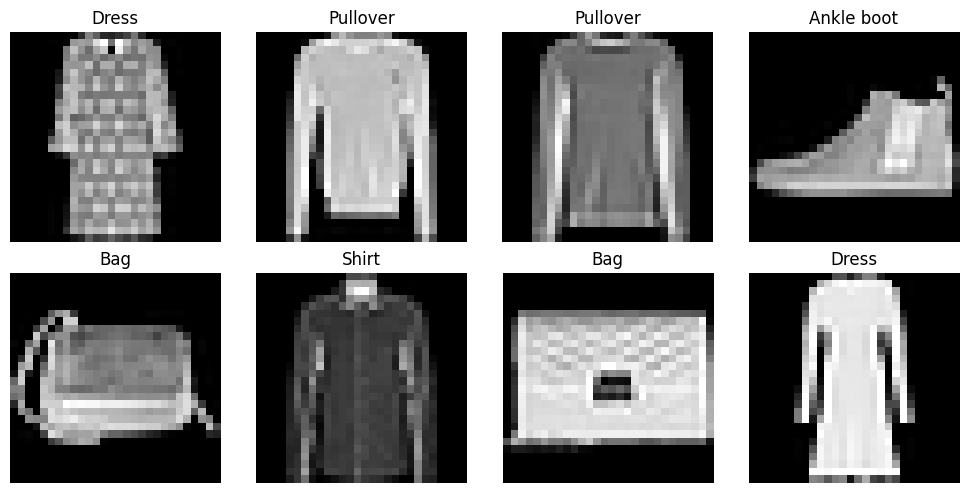

In [ ]:
plt.figure(figsize=(10, 5))
for i in range(8):
    ax = plt.subplot(2, 4, i + 1)
    rand_idx = random.randint(0, len(train_dataset) - 1)
    image, label = train_dataset[rand_idx]
    image = image.permute(1, 2, 0)
    plt.imshow(image, cmap='gray')
    plt.title(train_dataset.classes[label])
    plt.axis("off")
plt.tight_layout()
plt.show()

In [ ]:
test_transform = v2.Compose([
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True)
])

full_test_dataset = datasets.FashionMNIST(
    "/mydrive/data",
    download=True,
    train=False,
    transform=test_transform
)

# Split test dataset 50/50 into validation and test subsets
val_size = len(full_test_dataset) // 2
test_size = len(full_test_dataset) - val_size
val_dataset, test_dataset = random_split(full_test_dataset, [val_size, test_size])

print(f"Validation set size: {len(val_dataset)}")
print(f"Test set size: {len(test_dataset)}")

Validation set size: 5000
Test set size: 5000


KL-divergence for multivariate Gaussian distributions:

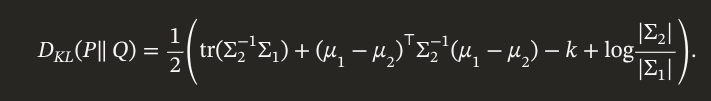

VAE case (prior - standard normal distribution), k - number of dimensions:
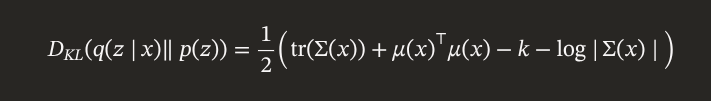

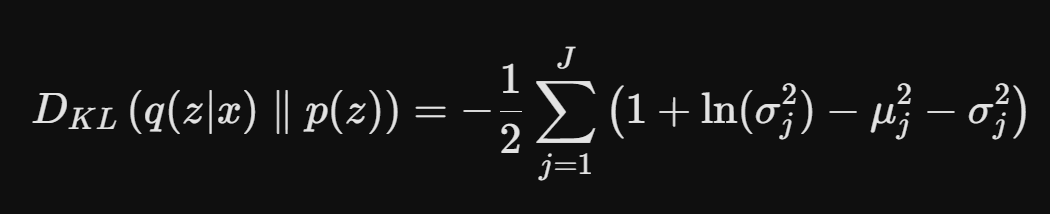

ELBO (Loss function):

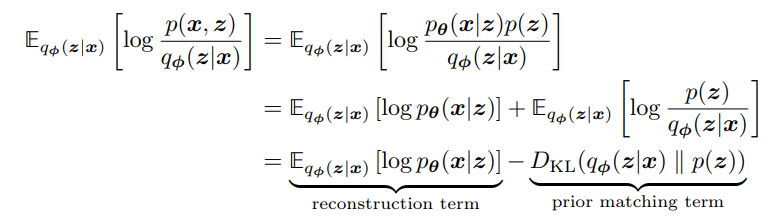

# Model

In [ ]:
class VAE(nn.Module):
    def __init__(self, channels, height, width, hid_dim: int):
        super().__init__()

        self.h = height
        self.w = width
        self.c = channels
        self.hid_dim = hid_dim

        self.encoder = nn.Sequential(
            # Optimization: disable bias in layers that go before BatchNorm because
            # it subtracts the mean and effectively cancells out bias parameter.
            # This saves space and compute.
            nn.Linear(height * width * channels, 512, bias=False),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Linear(512, 256, bias=False),
            nn.BatchNorm1d(256),
            nn.ReLU(),
        )

        # mean, log(sigma^2)
        self.fc = nn.Linear(256, hid_dim * 2)

        # should I use batchnorm in vae decoder, and should I use it in vae at all?
        self.decoder = nn.Sequential(
            nn.Linear(hid_dim, 256),
            nn.ReLU(),
            nn.Linear(256, 512),
            nn.ReLU(),
            nn.Linear(512, height * width * channels),
        )

    def encode(
        self, x: Float[Tensor, "B D"]
    ) -> tuple[Float[Tensor, "B D"], Float[Tensor, "B D"]]:
        mean, log_var = self.fc(self.encoder(x)).chunk(2, dim=-1)  # B, hid_dim
        return mean, log_var

    def sample(
        self,
        mean: Float[Tensor, "B D"],
        log_var: Float[Tensor, "B D"],
    ) -> Float[Tensor, "B D"]:
        std = torch.exp(log_var / 2)
        eps = torch.randn_like(mean)
        return mean + eps * std

    def decode(self, z) -> Float[Tensor, "B D"]:
        return self.decoder(z)

    def forward(self, x: Float[Tensor, "B C H W"]) -> tuple[Tensor, Tensor, Tensor]:
        B, C, H, W = x.shape

        x: Float[Tensor, "B D"] = x.flatten(start_dim=1)
        mean, log_var = self.encode(x)
        z = self.sample(mean, log_var)
        x_out = self.decode(z).view(B, C, H, W)
        x_out = torch.sigmoid(x_out)  # normalize output values

        return x_out, mean, log_var

    def generate(self) -> Float[Tensor, "B C H W"]:
        device = next(self.parameters()).device
        C, H, W = self.c, self.h, self.w
        z = torch.randn(1, self.hid_dim, device=device)

        x_out = self.decode(z).view(1, C, H, W)
        x_out = torch.sigmoid(x_out)  # normalize output values

        return x_out

In [ ]:
loader = DataLoader(train_dataset, batch_size=2)
ex = next(iter(loader))

In [ ]:
channels, height, width = ex[0][0].shape
hid_dim = 128

model = VAE(channels, height, width, hid_dim)
res = model(ex[0])
res[0].shape

torch.Size([2, 1, 28, 28])

In [ ]:
res[2]

tensor([[-0.0695, -0.6009, -0.2852, -0.0768, -0.1693,  0.0151,  0.5942,  0.5762,
         -0.3486, -0.0841,  0.1763,  0.6495,  0.3487,  0.3870,  0.0605, -0.5580,
          0.2871,  0.0650,  0.4035,  0.1811,  0.0450,  0.0042,  0.0023, -0.5251,
         -0.4638, -0.3801,  0.3878, -0.4706, -0.0814,  0.0125, -0.5579,  0.1951,
         -0.7083, -0.0520,  0.3959,  0.0043,  0.2232, -0.8103, -0.0280,  0.8628,
         -0.1696, -0.2200, -0.1253,  0.6432,  0.2334, -0.2207,  0.0840, -0.4833,
         -0.3383,  0.1422,  0.3569, -0.5668,  0.1644,  0.1215,  0.0372,  0.4700,
          0.1498,  0.1180,  0.5262, -0.1857, -0.3301,  0.6394, -0.1685, -0.5772,
         -0.3094, -0.3854,  0.0322, -0.2773, -0.4128,  0.4386, -0.2356, -0.1738,
          0.6865,  0.2794, -0.0779, -0.1147,  0.4938, -0.0416, -0.7470,  0.7307,
          0.0898, -0.3727, -0.0431, -0.0126,  0.3647,  0.0695, -0.6441,  0.3954,
          0.2477, -0.2457, -0.1960, -0.0052, -0.0959,  0.0634, -0.3099,  0.2142,
          0.1438, -0.3615,  

In [ ]:
def prior_matching_term(
    mean: Float[Tensor, "B D"],
    log_var: Float[Tensor, "B D"]
) -> Float[Tensor, "{1}"]:
    # Correct Analytical KL Divergence between N(mean, var) and N(0, I):
    # KL = -0.5 * sum(1 + log_var - mean^2 - exp(log_var))
    kl_loss = -0.5 * torch.sum(1 + log_var - mean.pow(2) - log_var.exp(), dim=-1)
    return kl_loss.mean()


def loss_fn(output, target, pm_beta=1.0):
    pm_loss = prior_matching_term(output[1], output[2])
    mse_loss = F.mse_loss(output[0], target, reduction='mean')
    # Minimizing the negative of ELBO: Minimize MSE + pm_alpha * KL
    return mse_loss + pm_beta * pm_loss, pm_loss, mse_loss

In [ ]:
prior_matching_term(res[1], res[2])

tensor(14.6535, grad_fn=<MeanBackward0>)

In [ ]:
F.mse_loss(res[0], ex[0])

tensor(0.1681, grad_fn=<MseLossBackward0>)

# Training

Posterior collapse - это явление в VAE, когда энкодер предсказывает просто случайный шум q(z|x) = p(z), а также декодер учится игнорировать z и генерировать просто p(x).

**Encoder - FC, Decoder - FC, Reconstruction term и KL имеют одинаковые веса в лоссе**. Результат - Posterior collapse: VAE генерирует просто белое пятно по центру, почти не отличающееся для разных x. Во время обучения KL упало очень быстро, за первые 20-30 итераций, намного быстрее, чем MSE (resonstruction term). Причина: энкодеру намного легче научиться выдавать случайный шум, чтобы минимизировать kl, чем декодеру минимизировать reconstruction loss научиться генерировать изображения - просто сама задача сложнее. Поэтому первым вырождается энкодер. Декодер вскоре понимает, что z из энкодера - это просто шум, который только мешает генерировать, и легче его просто игнорировать. В результате случайная компонента практически не влияет на выход и генерации получаются практически одинаковыми, почти константа. А если выход - константа, то лучшее значение для минимизации MSE - это среднее по всему датасету. И результаты генерации действительно похожи на среднее по датасету.

**beta-VAE: Encoder - FC, Decoder - FC, beta коэффициент у prior matching term = 0.005**. Результат - VAE генерирует изображения. Из-за маленького коэффициента энкодер обучается медленнее, а поэтому декодер успевает за энкодером и учится реконструировать изображения из скрытых представлений.

In [ ]:
device = torch.device(torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else 'cpu')
print(device)

cuda


In [ ]:
def create_device_dataset(raw_dataset: Dataset, device: torch.device | str) -> TensorDataset:
    """
    Extracts all data from a PyTorch Dataset, applies its transforms,
    and moves the entire dataset to the specified device.
    """
    # 1. Use the intermediate DataLoader to safely apply transforms to everything
    # Using batch_size=len(raw_dataset) processes it all in one go
    loader = DataLoader(raw_dataset, batch_size=len(raw_dataset), shuffle=False)

    # 2. Extract the batches (typically data and targets)
    # next(iter()) unpacks whatever the dataset returns (usually a tuple of tensors)
    batch = next(iter(loader))

    # 3. Move every tensor in the tuple to the device
    device_tensors = [tensor.to(device) for tensor in batch]

    # 4. Wrap the device tensors in a TensorDataset
    return TensorDataset(*device_tensors)

In [ ]:
train_device_dataset = create_device_dataset(train_dataset, device)
val_device_dataset = create_device_dataset(val_dataset, device)
test_device_dataset = test_dataset

Moving the datasets from VRAM to cuda in advance sped up one epoch from 20s to 5-6s.

VAE(
  (encoder): Sequential(
    (0): Linear(in_features=784, out_features=512, bias=False)
    (1): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Linear(in_features=512, out_features=256, bias=False)
    (4): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU()
  )
  (fc): Linear(in_features=256, out_features=256, bias=True)
  (decoder): Sequential(
    (0): Linear(in_features=128, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=512, bias=True)
    (3): ReLU()
    (4): Linear(in_features=512, out_features=784, bias=True)
  )
)
Saved model architecture to model_architecture.txt
Total Trainable Parameters: 1166608
--- Epoch 1/20 | pm_beta: 0.00500 ---
--> New best validation loss: 0.0685. Saved model state.
Epoch 1 finished in 5.86s | Train Loss: 0.0855 | Val Loss: 0.0685 (PM: 1.9939, MSE: 0.0586)
--- Epoch 2/20 | pm_beta: 0.00500 ---
--> Ne

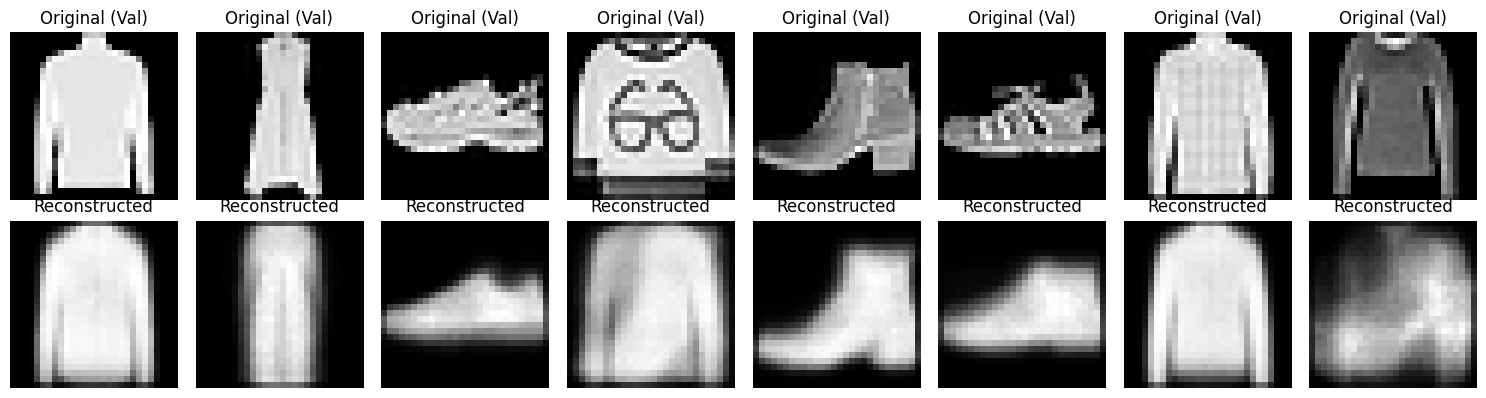

avg_gradient,▂▂▃▄▃▃▅▂▃▆▃▁▅▄▃▅▅▅▃▇▄▅▄▃▅▃▂▂█▄▄▅▄▇▄▃▅▄▆▇
epoch,▁▁▁▁▂▂▂▂▂▃▄▄▄▄▄▅▅▅▆▆▆▆▆▆▆▆▇▇▇▇▇▇▇▇▇▇████
iteration,▁▁▂▂▂▂▂▂▃▃▃▃▄▄▄▄▄▄▄▄▄▄▄▅▅▆▆▆▆▆▇▇▇▇▇█████
loss,██▅▆▅▄▃▄▄▄▄▄▄▃▃▃▄▂▃▂▂▂▁▃▂▁▂▃▁▂▂▂▂▂▂▁▁▂▁▂
mse_loss,█▅▅▄▅▅▃▄▃▄▃▄▂▃▃▁▂▂▂▁▁▃▂▂▁▁▁▂▂▁▂▂▂▁▂▃▁▁▂▁
pm_beta,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
prior_matching_loss,▁▄▄▅▄▅▅▆▅▆▅▆▆▆▇▇▇▆▆▇▇▇▇▇▇▇▇▇███████▇████
val_loss,█▇▇▆▅▄▄▃▂▂▂▂▁▁▁▁▁▁▁▁
val_mse_loss,█▇▇▆▅▄▄▃▂▂▂▂▂▂▁▁▁▁▁▁
val_prior_matching_loss,▁▃▃▄▄▅▅▆▅▆▇▇▇▇▇█████
avg_gradient,0.01302


avg_gradient,0.01302
epoch,20
iteration,18759
loss,0.0536
mse_loss,0.03866
pm_beta,0.005
prior_matching_loss,2.98853
val_loss,0.05145
val_mse_loss,0.03606
val_prior_matching_loss,3.07839


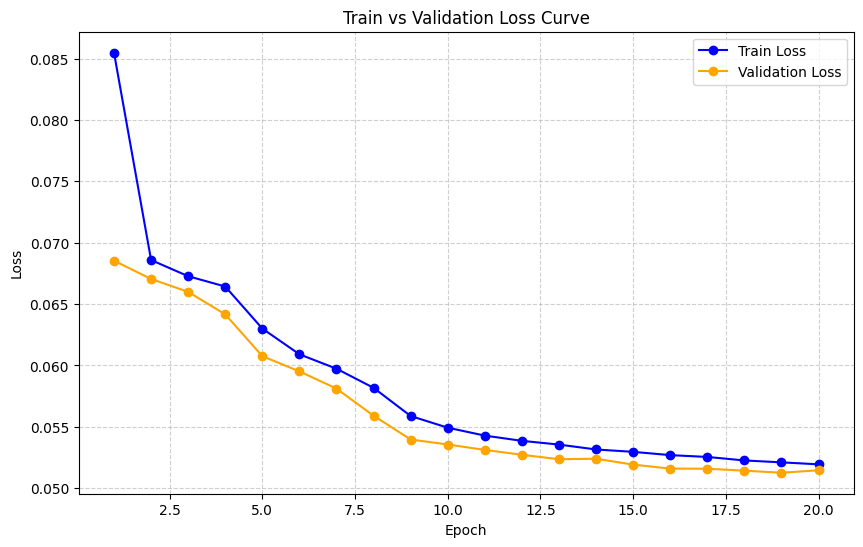

In [ ]:
run = wandb.init(
    entity="t4rwerka",
    project="custom_vae",
    config={
        "learning_rate": 0.0001,
        "epochs": 20,
        "batch_size": 64,
        "hid_dim": hid_dim,
        "min_pm_beta": 0.005,
        "max_pm_beta": 0.005,
        "warmup_epochs": 10,
        "dataset": "FashionMNIST"
    }
)

# shuffle=True shuffles the dataset at every epoch
train_dataloader = DataLoader(train_device_dataset, batch_size=run.config.batch_size, shuffle=True)
val_dataloader = DataLoader(val_device_dataset, batch_size=len(val_dataset), shuffle=False)
# test_dataloader = DataLoader(test_device_dataset, batch_size=len(test_dataset), shuffle=False)


model = VAE(channels, height, width, hid_dim).to(device)
optimizer = optim.Adam(model.parameters(), lr=run.config.learning_rate)

model_architecture_str = str(model)
print(model_architecture_str)

# Save model architecture to a text file
with open("model_architecture.txt", "w") as f:
    f.write(model_architecture_str)
print("Saved model architecture to model_architecture.txt")

total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total Trainable Parameters: {total_params}")

wandb.config.update({
    "model_architecture": model_architecture_str,
    "total_parameters": total_params
})

wandb.watch(model, log="all", log_freq=100)

iteration = 0
best_val_loss = float('inf')
best_model_state = None

train_losses = []
val_losses = []

for epoch in range(run.config.epochs):
    epoch_start_time = time.time()

    model.train()
    epoch_train_loss = 0.0
    num_train_batches = 0

    min_beta = run.config.min_pm_beta
    max_beta = run.config.max_pm_beta
    pm_beta = min(max_beta, min_beta + (max_beta - min_beta) / run.config.warmup_epochs * epoch)

    print(f"--- Epoch {epoch + 1}/{run.config.epochs} | pm_beta: {pm_beta:.5f} ---")

    for x, _ in train_dataloader:
        start_time = time.time()
        x = x.to(device)
        optimizer.zero_grad()

        out = model(x)
        loss, pm_loss, mse_loss = loss_fn(out, x, pm_beta=pm_beta)

        loss.backward()

        # Calculate average gradient
        total_grad_norm = 0
        num_params = 0
        for param in model.parameters():
            if param.grad is not None:
                total_grad_norm += param.grad.data.norm(2).item()
                num_params += 1
        avg_grad = total_grad_norm / num_params if num_params > 0 else 0.0

        optimizer.step()

        epoch_train_loss += loss.item()
        num_train_batches += 1

        wandb.log({
            "loss": loss.item(),
            "prior_matching_loss": pm_loss.item(),
            "mse_loss": mse_loss.item(),
            "avg_gradient": avg_grad,
            "pm_beta": pm_beta,
            "epoch": epoch + 1,
            "iteration": iteration
        })
        iteration += 1

    # Calculate epoch training average
    avg_train_loss = epoch_train_loss / num_train_batches
    train_losses.append(avg_train_loss)

    # Validation Phase
    model.eval()
    epoch_val_loss = 0.0
    epoch_val_pm_loss = 0.0
    epoch_val_mse_loss = 0.0
    num_val_batches = 0

    with torch.no_grad():
        for val_x, _ in val_dataloader:
            val_x = val_x.to(device)
            val_out = model(val_x)
            v_loss, v_pm_loss, v_mse_loss = loss_fn(val_out, val_x, pm_beta=pm_beta)

            epoch_val_loss += v_loss.item()
            epoch_val_pm_loss += v_pm_loss.item()
            epoch_val_mse_loss += v_mse_loss.item()
            num_val_batches += 1

    avg_val_loss = epoch_val_loss / num_val_batches
    avg_val_pm_loss = epoch_val_pm_loss / num_val_batches
    avg_val_mse_loss = epoch_val_mse_loss / num_val_batches
    val_losses.append(avg_val_loss)

    # Track the best model state based on validation loss
    if avg_val_loss < best_val_loss:
        best_val_loss = avg_val_loss
        best_model_state = copy.deepcopy(model.state_dict())
        print(f"--> New best validation loss: {best_val_loss:.4f}. Saved model state.")

    # Log validation metrics to W&B
    wandb.log({
        "val_loss": avg_val_loss,
        "val_prior_matching_loss": avg_val_pm_loss,
        "val_mse_loss": avg_val_mse_loss,
        "epoch": epoch + 1
    })

    # Generate and log sample image every epoch
    with torch.no_grad():
        gen_img = model.generate().squeeze(0).cpu()
        wandb_img = wandb.Image(gen_img, caption=f"Epoch {epoch + 1} Generation")
        wandb.log({"epoch_generated_samples": wandb_img}, commit=False)

    epoch_duration = time.time() - epoch_start_time
    print(f"Epoch {epoch + 1} finished in {epoch_duration:.2f}s | Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f} (PM: {avg_val_pm_loss:.4f}, MSE: {avg_val_mse_loss:.4f})")

if best_model_state is not None:
    model.load_state_dict(best_model_state)
    print("Loaded the best model state based on minimum validation loss.")

# Create final original vs reconstruction plot for 8 validation examples
num_examples = 8
fig, axes = plt.subplots(2, num_examples, figsize=(15, 4))
example_indices = random.sample(range(len(val_dataset)), num_examples)

model.eval()
for i, idx in enumerate(example_indices):
    original_image, _ = val_dataset[idx]
    input_image = original_image.unsqueeze(0).to(device)

    with torch.no_grad():
        reconstructed_image, _, _ = model(input_image)

    axes[0, i].imshow(original_image.permute(1, 2, 0).cpu().squeeze(), cmap='gray')
    axes[0, i].set_title("Original (Val)")
    axes[0, i].axis('off')

    axes[1, i].imshow(reconstructed_image.permute(0, 2, 3, 1).cpu().squeeze(), cmap='gray')
    axes[1, i].set_title("Reconstructed")
    axes[1, i].axis('off')

plt.tight_layout()
wandb.log({"final_reconstruction_plot": wandb.Image(plt)})
plt.show()

# Unwatch the model so that W&B removes its telemetry tracking hooks (for gradients tracking, etc.)
# from the model, because pickle cannot serialize them, so that we can save the
# whole `model` (parameters and architecture)
wandb.unwatch(model)

wandb.finish()

# Log train/val plot
plt.figure(figsize=(10, 6))
plt.plot(range(1, len(train_losses) + 1), train_losses, label='Train Loss', color='blue', marker='o')
plt.plot(range(1, len(val_losses) + 1), val_losses, label='Validation Loss', color='orange', marker='o')
plt.title('Train vs Validation Loss Curve')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()

# Log the loss plot to wandb if a run is active
if wandb.run is not None:
    wandb.log({"loss_curve": wandb.Image(plt)})
else:
    # If the run was already finished, we re-initialize briefly to log the artifact
    with wandb.init(entity="t4rwerka", project="custom_vae", id=run.id, resume="must") as re_run:
        re_run.log({"loss_curve": wandb.Image(plt)})

plt.show()

Save the best model and the architecture txt

In [ ]:
# 1. Define local paths and save only the FULL model object
FULL_MODEL_PATH = "vae_full_model.pt"
torch.save(model, FULL_MODEL_PATH)
print(f"Saved full model object locally to {FULL_MODEL_PATH}")

# 2. Resume the exact training run to log the artifact to it
# We fetch the run ID from the cell above where the training took place
run = wandb.init(
    entity="t4rwerka",
    project="custom_vae",
    id=run.id,
    resume="must"
)

# 3. Create a W&B Artifact
model_artifact = wandb.Artifact(
    name="vae_fashion_mnist",
    type="model",
    description="Best full model object and architecture of the custom VAE"
)

# 4. Add files to the artifact
model_artifact.add_file(FULL_MODEL_PATH)

ARCH_PATH = "model_architecture.txt"
if os.path.exists(ARCH_PATH):
    model_artifact.add_file(ARCH_PATH)
    print(f"Added {ARCH_PATH} to the artifact.")

run.log_artifact(model_artifact)
print("Successfully logged model artifact to the training run!")

# 5. Finish the resumed run session
run.finish()

# 6. Clean up local files (optional)
os.remove(FULL_MODEL_PATH)
if os.path.exists(ARCH_PATH):
    os.remove(ARCH_PATH)

Saved full model object locally to vae_full_model.pt


Added model_architecture.txt to the artifact.
Successfully logged model artifact to the training run!


avg_gradient,0.01302
epoch,20
iteration,18759
loss,0.0536
mse_loss,0.03866
pm_beta,0.005
prior_matching_loss,2.98853
val_loss,0.05145
val_mse_loss,0.03606
val_prior_matching_loss,3.07839


# Load model from experiment

In [ ]:
# 1. Setup API key and authenticate
os.environ['WANDB_API_KEY'] = userdata.get("WANDB_API_KEY")
api = wandb.Api()

# 2. Specify your exact project path and Run ID
project_path = "t4rwerka/custom_vae"
specific_run_id = "o03oxvxl"

try:
    # Fetch the run details from the W&B API
    run = api.run(f"{project_path}/{specific_run_id}")
    print(f"Successfully fetched Run: {run.name} (ID: {run.id})")

    # 3. Get and download the logged model artifact
    logged_artifacts = run.logged_artifacts()
    model_artifacts = [art for art in logged_artifacts if art.type == "model"]

    if not model_artifacts:
        raise ValueError(f"No model artifacts found logged under run {specific_run_id}")

    target_artifact = model_artifacts[0]
    artifact_dir = target_artifact.download()
    print(f"Artifact downloaded to: {artifact_dir}")

except Exception as e:
    print(f"Error fetching run or downloading artifact: {e}")
    print("\nFalling back to default latest artifact for demonstration...")
    run = wandb.init(entity="t4rwerka", project="custom_vae", job_type="download_model")
    artifact = run.use_artifact("t4rwerka/custom_vae/vae_fashion_mnist:latest", type="model")
    artifact_dir = artifact.download()
    run.finish()

# 4. Directly load the entire model object (no class definition needed!)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
full_model_file_path = os.path.join(artifact_dir, "vae_full_model.pt")

if os.path.exists(full_model_file_path):
    # Loading the full serialized model
    model = torch.load(full_model_file_path, map_location=device)
    model.eval()
    print("Entire model successfully loaded without needing class definitions!")
else:
    print(f"Full model file not found at {full_model_file_path}. Please run the updated logging cell first.")

Successfully fetched Run: beta-VAE (batch norm) (ID: o03oxvxl)


wandb:   2 of 2 files downloaded.  


Artifact downloaded to: /content/artifacts/vae_fashion_mnist:v2


UnpicklingError: Weights only load failed. This file can still be loaded, to do so you have two options, [1mdo those steps only if you trust the source of the checkpoint[0m. 
	(1) In PyTorch 2.6, we changed the default value of the `weights_only` argument in `torch.load` from `False` to `True`. Re-running `torch.load` with `weights_only` set to `False` will likely succeed, but it can result in arbitrary code execution. Do it only if you got the file from a trusted source.
	(2) Alternatively, to load with `weights_only=True` please check the recommended steps in the following error message.
	WeightsUnpickler error: Unsupported global: GLOBAL __main__.VAE was not an allowed global by default. Please use `torch.serialization.add_safe_globals([__main__.VAE])` or the `torch.serialization.safe_globals([__main__.VAE])` context manager to allowlist this global if you trust this class/function.

Check the documentation of torch.load to learn more about types accepted by default with weights_o

avg_gradient,0.01463
epoch,20
iteration,18759
loss,0.04862
mse_loss,0.03357
prior_matching_loss,3.00929
val_loss,0.05078
val_mse_loss,0.03531
val_prior_matching_loss,3.09429


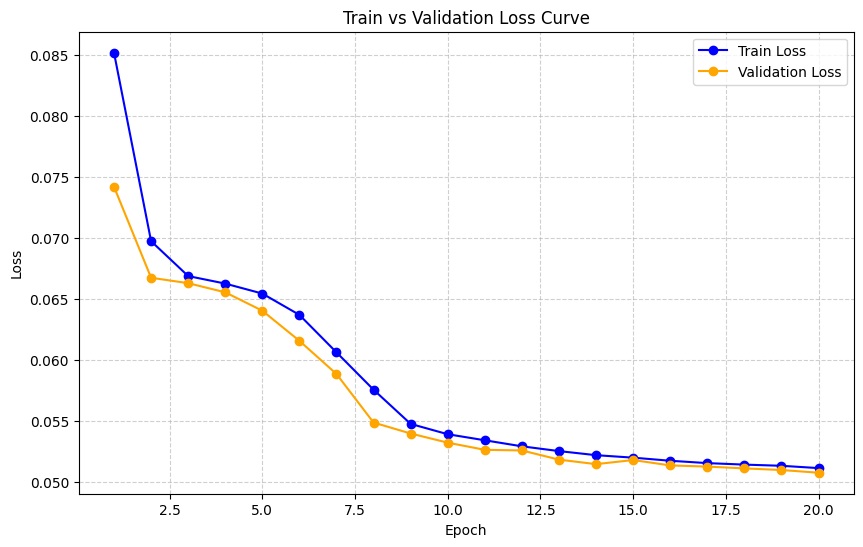

Среднее по всем картинкам из датасета (очень похоже на то, что генерирует энкодер когда происходит Posterior collapse):

In [ ]:
total_image_sum = torch.zeros_like(train_dataset[0][0])
total_images_count = 0

for image, _ in train_dataset:
    total_image_sum += image
    total_images_count += 1

average_image = total_image_sum / total_images_count

plt.figure(figsize=(5, 5))
plt.imshow(average_image.permute(1, 2, 0).squeeze(), cmap='gray')
plt.title("Average Image across the Dataset")
plt.axis("off")
plt.show()